# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser
**OOP with Python: Assignment 1, Advent 2026**

**Scenario.** An agricultural extension officer wants to compare rainfall regimes across regions and advise farmers on which months suit which crops.

## How this notebook is organised
| Section | What we build | Main idea |
|---|---|---|
| 0 | Imports and data | Set-up |
| 1 | `Region` class | Wrap data + behaviour together |
| 2 | `CropRule` class | Rules that act on a `Region` |
| 3 | Cosine similarity, done right | Why `math.cos()` is wrong |
| 4 | Similarity / distance matrices | Cosine vs Pearson vs Euclidean |
| 5 | Rainy-season detection | `scipy.signal.find_peaks` |
| 6 | Visualisation | Line chart + suitability heatmap |
| 7 | Advisory note | Turning numbers into advice |
| Ext | Box plots of year-to-year variability | Reusable plotting function |

**Code layout:** the reusable classes and functions live in `src/rainfall/` and are imported below; this notebook only *uses* them. It runs top to bottom with *Restart & Run All*.

**Reusability:** every class and function takes its inputs as arguments (no hidden globals). To analyse new regions or crops, change only the data in Section 0 or the crop list in Section 2.

## 0. Set-up: imports and data

In [1]:
import sys
sys.path.insert(0, "src")                     # lets us import our package from the src/ folder

import math                                   # only used to show the flawed method in Section 3

import numpy as np                            # fast arrays and maths
import pandas as pd                           # tables

from scipy.spatial import distance            # used to VERIFY our own cosine similarity (Section 3)

# Our own reusable code (see src/rainfall/)
from rainfall import (MONTHS, Region, CropRule, classification_table,
                      cosine_similarity, euclidean_distance, pearson_correlation,
                      pairwise_matrix, find_rainy_seasons, classify_seasonality)
from rainfall.plots import plot_rainfall_lines, plot_suitability_heatmap, plot_monthly_boxplots

In [2]:
# MONTHS is imported from src/rainfall/constants.py
# Illustrative monthly rainfall in mm (Jan-Dec), straight from the brief.
# A dictionary {region name: 12 monthly values} makes it easy to add a region later.
RAINFALL_DATA = {
    "Kampala": [120, 140, 180, 200, 220, 180,  90,  70,  60, 100, 110, 130],
    "Gulu":    [  8,  25,  75, 160, 190, 145, 170, 215, 175, 150,  60,  15],
    "Mbarara": [ 70,  85, 120, 140,  90,  25,  20,  55, 100, 125, 120,  90],
}

## 1. The `Region` class

**Task 1.** A class that holds a region's rainfall as a NumPy array and has methods for annual total, mean, wettest/driest month and coefficient of variation.

**Design idea.** A class bundles *data* (`name`, `rainfall`) with the *functions that work on that data* (methods). Once a `Region` exists, anyone can call `kampala.annual_total()` without knowing how it is computed.

**Coefficient of variation (CV)** = standard deviation ÷ mean × 100. It tells us how *uneven* rainfall is across months, as a percentage of the average. A high CV means a strongly seasonal climate (very wet months and very dry months).

In [3]:
# The Region class lives in src/rainfall/region.py (imported above).
print(Region.__doc__)

A geographic region with 12 months of rainfall (mm).

Attributes
----------
name : str
    Region name, e.g. "Kampala".
rainfall : numpy.ndarray
    Array of 12 monthly rainfall values in mm (January to December).



In [4]:
# Build one Region object per entry in the data dictionary
regions = [Region(name, values) for name, values in RAINFALL_DATA.items()]

# Put every region's summary into one table
summary_table = pd.DataFrame([r.summary() for r in regions]).set_index("Region")
summary_table

,Annual total (mm),Monthly mean (mm),Wettest month,Driest month,CV (%)
Region,,,,,
Kampala,1600.0,133.3,May (220 mm),Sep (60 mm),37.2
Gulu,1388.0,115.7,Aug (215 mm),Jan (8 mm),61.4
Mbarara,1040.0,86.7,Apr (140 mm),Jul (20 mm),42.5


**Reading the table.** Gulu has the most uneven rainfall (highest CV): nearly dry in January (8 mm) and very wet in August (215 mm). Kampala is the most evenly spread.

## 2. The `CropRule` class

**Task 2.** Define at least three crops with rainfall thresholds justified by a cited source, then classify every month in every region.

**Simplest design.** Each crop gets one *suitable range* `[min_mm, max_mm]` of monthly rainfall:

* below `min_mm` → **Drought risk**
* above `max_mm` → **Waterlogging risk**
* in between → **Good for <crop>**

**Where the numbers come from.** The monthly ranges below are *converted* from the seasonal and annual water needs reported by FAO:

| Crop | Source figure | Monthly range used |
|---|---|---|
| Maize | about 500-800 mm per growing season (about 4 months), FAO Irrigation & Drainage Paper 33 (Doorenbos & Kassam, 1979) | 100-200 mm |
| Beans | about 300-500 mm per growing season (2.5-3 months), same FAO paper | 75-150 mm |
| Robusta coffee | about 1,000-3,000 mm per year, FAO EcoCrop database | 85-250 mm |

> ⚠️ **Before you submit:** open the two FAO sources and confirm the figures and page numbers yourself; I could not open them while preparing this notebook. The conversion to monthly values is my simplification (seasonal need ÷ season length). If your lecturer or a Ugandan source (e.g. NARO) gives different ranges, just edit the three numbers in `crops` below, as nothing else needs to change.

In [5]:
# The CropRule class lives in src/rainfall/crop_rules.py (imported above).
print(CropRule.__doc__)

Rainfall rule for one crop: a suitable range of monthly rainfall (mm).

Parameters
----------
crop : str
    Crop name, e.g. "Maize".
min_mm, max_mm : float
    Lowest and highest monthly rainfall that still suits the crop.
source : str
    Citation that justifies the thresholds.



In [6]:
# The three crops. Edit the numbers here to change the analysis.
crops = [
    CropRule("Maize", 100, 200,
             "FAO Irrigation & Drainage Paper 33 (Doorenbos & Kassam, 1979): ~500-800 mm per season"),
    CropRule("Beans", 75, 150,
             "FAO Irrigation & Drainage Paper 33 (Doorenbos & Kassam, 1979): ~300-500 mm per season"),
    CropRule("Coffee", 85, 250,
             "FAO EcoCrop database, Coffea canephora (Robusta): ~1,000-3,000 mm per year"),
]

# Show the rules as a table
pd.DataFrame([{"Crop": c.crop, "Min (mm/month)": c.min_mm,
               "Max (mm/month)": c.max_mm, "Source": c.source} for c in crops]).set_index("Crop")

,Min (mm/month),Max (mm/month),Source
Crop,,,
Maize,100,200,FAO Irrigation & Drainage Paper 33 (Doorenbos ...
Beans,75,150,FAO Irrigation & Drainage Paper 33 (Doorenbos ...
Coffee,85,250,"FAO EcoCrop database, Coffea canephora (Robust..."


In [7]:
labels_table = classification_table(regions, crops)   # function from src/rainfall/crop_rules.py
labels_table

Jan              Feb                Mar  \
Kampala Maize    Good for maize   Good for maize     Good for maize   
        Beans    Good for beans   Good for beans  Waterlogging risk   
        Coffee  Good for coffee  Good for coffee    Good for coffee   
Gulu    Maize      Drought risk     Drought risk       Drought risk   
        Beans      Drought risk     Drought risk     Good for beans   
        Coffee     Drought risk     Drought risk       Drought risk   
Mbarara Maize      Drought risk     Drought risk     Good for maize   
        Beans      Drought risk   Good for beans     Good for beans   
        Coffee     Drought risk  Good for coffee    Good for coffee   

                              Apr                May                Jun  \
Kampala Maize      Good for maize  Waterlogging risk     Good for maize   
        Beans   Waterlogging risk  Waterlogging risk  Waterlogging risk   
        Coffee    Good for coffee    Good for coffee    Good for coffee   
Gulu    Maize      Good for maize     Good for maize     Good for maize   
        Beans   Waterlogging risk  Waterlogging risk     Good for beans   
        Coffee    Good for coffee    Good for coffee    Good for coffee   
Mbarara Maize      Good for maize       Drought risk       Drought risk   
        Beans      Good for beans     Good for beans       Drought risk   
        Coffee    Good for coffee    Good for coffee       Drought risk   

                              Jul                Aug                Sep  \
Kampala Maize        Drought risk       Drought risk       Drought risk   
        Beans      Good for beans       Drought risk       Drought risk   
        Coffee    Good for coffee       Drought risk       Drought risk   
Gulu    Maize      Good for maize  Waterlogging risk     Good for maize   
        Beans   Waterlogging risk  Waterlogging risk  Waterlogging risk   
        Coffee    Good for coffee    Good for coffee    Good for coffee   
Mbarara Maize        Drought risk       Drought risk     Good for maize   
        Beans        Drought risk       Drought risk     Good for beans   
        Coffee       Drought risk       Drought risk    Good for coffee   

                            Oct              Nov              Dec  
Kampala Maize    Good for maize   Good for maize   Good for maize  
        Beans    Good for beans   Good for beans   Good for beans  
        Coffee  Good for coffee  Good for coffee  Good for coffee  
Gulu    Maize    Good for maize     Drought risk     Drought risk  
        Beans    Good for beans     Drought risk     Drought risk  
        Coffee  Good for coffee     Drought risk     Drought risk  
Mbarara Maize    Good for maize   Good for maize     Drought risk  
        Beans    Good for beans   Good for beans   Good for beans  
        Coffee  Good for coffee  Good for coffee  Good for coffee

## 3. Cosine similarity: fixing last year's flawed method

**Task 3.** Last year's question used `math.cos()`. Why is that wrong?

* `math.cos(x)` takes **one number** `x` (an *angle* in radians) and returns the cosine of that angle.
* **Cosine similarity** compares **two vectors**. It is the cosine of the angle *between* them, and we never have that angle directly. We get it from the formula:

$$\cos(\theta) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

(dot product divided by the product of the vector lengths). Notice the formula *already gives* the cosine. Wrapping it in `math.cos()` again takes the cosine of a cosine, which is meaningless.

In [8]:
# cosine_similarity (the CORRECT method) is imported from src/rainfall/similarity.py.
# The flawed version stays here, because it exists only to demonstrate the mistake.
def cosine_similarity_flawed(a, b):
    """THE WRONG WAY (for demonstration only): applies math.cos() on top of the formula."""
    ratio = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return math.cos(ratio)          # <- cosine of a cosine: wrong

In [9]:
kampala, gulu, mbarara = regions

# Mistake 1: math.cos() cannot even accept a vector
try:
    math.cos(kampala.rainfall)
except TypeError as error:
    print("math.cos(vector) fails ->", error)

# Mistake 2: when it does run, the answer is wrong.
# A vector is perfectly similar to itself, so the answer must be exactly 1.
print("\nKampala vs Kampala")
print("  correct :", cosine_similarity(kampala.rainfall, kampala.rainfall))
print("  flawed  :", round(cosine_similarity_flawed(kampala.rainfall, kampala.rainfall), 4), "<- should be 1")

math.cos(vector) fails -> only length-1 arrays can be converted to Python scalars

Kampala vs Kampala
  correct : 1.0
  flawed  : 0.5403 <- should be 1


In [10]:
# VERIFY our function against SciPy.
# scipy returns cosine DISTANCE, and distance = 1 - similarity.
pairs = [(kampala, gulu), (kampala, mbarara), (gulu, mbarara)]

for r1, r2 in pairs:
    ours = cosine_similarity(r1.rainfall, r2.rainfall)
    scipys = 1 - distance.cosine(r1.rainfall, r2.rainfall)
    assert np.isclose(ours, scipys), "Mismatch with SciPy!"
    print(f"{r1.name:8s} vs {r2.name:8s}  ours = {ours:.6f}   scipy = {scipys:.6f}   match: {np.isclose(ours, scipys)}")

Kampala  vs Gulu      ours = 0.786609   scipy = 0.786609   match: True
Kampala  vs Mbarara   ours = 0.891250   scipy = 0.891250   match: True
Gulu     vs Mbarara   ours = 0.748678   scipy = 0.748678   match: True


## 4. Three ways to compare regions

**Task 4.** Compute cosine similarity, Pearson correlation and Euclidean distance for every pair of regions, shown as matrices.

| Measure | Question it answers | Range | Cares about size (mm)? |
|---|---|---|---|
| Cosine similarity | Do the two curves point in the same *direction*? | -1 to 1 (higher = more similar) | **No** |
| Pearson correlation | Do the two curves rise and fall *together*? | -1 to 1 | **No** |
| Euclidean distance | How far apart are the curves in mm? | 0 upward (lower = more similar) | **Yes** |

Because all three need the same "compare every pair" loop, we write that loop **once** (`pairwise_matrix`) and pass in the measure as an argument. Functions can be passed around like any other value, and that is what makes the code reusable.

In [11]:
# euclidean_distance, pearson_correlation and pairwise_matrix come from src/rainfall/similarity.py
cosine_matrix    = pairwise_matrix(regions, cosine_similarity)
pearson_matrix   = pairwise_matrix(regions, pearson_correlation)
euclidean_matrix = pairwise_matrix(regions, euclidean_distance)

print("Cosine similarity (1 = same shape)")
print(cosine_matrix.round(3), "\n")
print("Pearson correlation (1 = rise and fall together)")
print(pearson_matrix.round(3), "\n")
print("Euclidean distance in mm (0 = identical)")
print(euclidean_matrix.round(1))

Cosine similarity (1 = same shape)
         Kampala   Gulu  Mbarara
Kampala    1.000  0.787    0.891
Gulu       0.787  1.000    0.749
Mbarara    0.891  0.749    1.000 

Pearson correlation (1 = rise and fall together)
         Kampala   Gulu  Mbarara
Kampala    1.000 -0.066    0.209
Gulu      -0.066  1.000   -0.174
Mbarara    0.209 -0.174    1.000 

Euclidean distance in mm (0 = identical)
         Kampala   Gulu  Mbarara
Kampala      0.0  315.3    250.4
Gulu       315.3    0.0    312.8
Mbarara    250.4  312.8      0.0


### Why can cosine similarity call two regions "similar" when one is much wetter?

Cosine similarity measures only the **angle** between two vectors, not their **length**. If one region receives exactly twice the rainfall of another in every month, the two vectors point in the *same direction* (same seasonal shape), so cosine similarity is a perfect 1, even though one region is far wetter. The demo below proves it.

A second reason: rainfall is never negative, so all the vectors sit in the same "corner" of the space and cosine similarity tends to come out high for *any* pair of regions. Compare the matrices above: cosine says Kampala and Mbarara are 0.89 alike, while Pearson (which first subtracts each region's average) says only about 0.2.

**Practical rule:** use cosine or Pearson to compare *seasonal shape*, and Euclidean distance when the *amount* of rain matters. For crop advice, amounts matter, so cosine alone would be misleading.

In [12]:
# A "twin" of Kampala that is exactly twice as wet in every month
twin = Region("Kampala x2", kampala.rainfall * 2)

print("Kampala vs its double-wet twin")
print(f"  Cosine similarity  : {cosine_similarity(kampala.rainfall, twin.rainfall):.3f}  <- 'identical'")
print(f"  Pearson correlation: {pearson_correlation(kampala.rainfall, twin.rainfall):.3f}  <- also 'identical'")
print(f"  Euclidean distance : {euclidean_distance(kampala.rainfall, twin.rainfall):.1f} mm  <- sees the difference")
print(f"  Annual totals      : {kampala.annual_total():.0f} mm vs {twin.annual_total():.0f} mm")

Kampala vs its double-wet twin
  Cosine similarity  : 1.000  <- 'identical'
  Pearson correlation: 1.000  <- also 'identical'
  Euclidean distance : 492.7 mm  <- sees the difference
  Annual totals      : 1600 mm vs 3200 mm


## 5. Detecting rainy seasons automatically

**Task 5.** Use `scipy.signal.find_peaks` to find rainy seasons, and classify each region as **unimodal** (one rainy season) or **bimodal** (two).

**Two details that matter:**

1. **Prominence.** A tiny bump is not a "season". `find_peaks(..., prominence=P)` keeps only peaks that rise at least `P` mm above the surrounding dips.
2. **The year is a circle.** December is followed by January. A plain `find_peaks` call can never report January or December as a peak, because it ignores the two ends of the array. To fix this we **repeat the year three times**, search the middle copy, and ignore the outer copies.

In [13]:
# find_rainy_seasons and classify_seasonality come from src/rainfall/seasons.py
help(find_rainy_seasons)

Help on function find_rainy_seasons in module rainfall.seasons:

find_rainy_seasons(rainfall: 'ArrayLike', min_prominence: 'float' = 40) -> 'tuple[NDArray, NDArray]'
    Find the rainy-season peaks in 12 months of rainfall.

    Parameters
    ----------
    rainfall : array of 12 monthly values (mm).
    min_prominence : float
        Minimum height (mm) a peak must stand above its surroundings to count
        as a rainy season. This is the one setting you may need to tune.

    Returns
    -------
    (month_positions, prominences) : two arrays, one entry per season found.



In [14]:
# What does each region look like to the detector?
# Reference: commonly described Uganda rainfall zones (CHECK against a source such as UNMA before submitting):
#   central & south-west (Kampala, Mbarara) -> two seasons (about Mar-May and Sep-Nov)
#   northern (Gulu)                         -> mostly one long season (about Apr-Oct)
KNOWN_ZONES = {"Kampala": "bimodal", "Gulu": "unimodal", "Mbarara": "bimodal"}

rows = []
for region in regions:
    positions, prominences = find_rainy_seasons(region.rainfall, min_prominence=40)
    found = classify_seasonality(region.rainfall, min_prominence=40)
    rows.append({
        "Region": region.name,
        "Peak months": ", ".join(MONTHS[p] for p in positions),
        "Prominences (mm)": ", ".join(f"{p:.0f}" for p in prominences),
        "Detected": found,
        "Known zone": KNOWN_ZONES[region.name],
        "Match?": "yes" if found == KNOWN_ZONES[region.name] else "NO",
    })

pd.DataFrame(rows).set_index("Region")

,Peak months,Prominences (mm),Detected,Known zone,Match?
Region,,,,,
Kampala,May,160,unimodal,bimodal,NO
Gulu,"May, Aug","45, 207",bimodal,unimodal,NO
Mbarara,"Apr, Oct","120, 55",bimodal,bimodal,yes


### Does the result match Uganda's known climate zones?

Not for every region, and **that is an honest finding rather than a bug**. Print the table above and read it with these points in mind:

* **Mbarara** shows two seasons (March-May and September-November), matching its known bimodal pattern.
* **Kampala** is known to be bimodal, but the illustrative data has no real December-February dry spell (110-140 mm), so the second peak is barely above its surroundings and is filtered out.
* **Gulu** is usually described as having one long rainy season, but the illustrative data has a mid-season dip big enough to create a second peak.

The detector is doing its job; the *made-up data* does not perfectly reproduce real climates. The table below shows how sensitive the verdict is to the prominence setting, which is why the extension task (real multi-year data) is worth doing.

In [15]:
# Sensitivity check: how many seasons does each region show at different prominence settings?
thresholds = [10, 20, 30, 40, 50, 60, 80]

sensitivity = pd.DataFrame(
    {r.name: [len(find_rainy_seasons(r.rainfall, t)[0]) for t in thresholds] for r in regions},
    index=pd.Index(thresholds, name="min prominence (mm)"),
)
sensitivity

,Kampala,Gulu,Mbarara
min prominence (mm),,,
10,2,2,2
20,1,2,2
30,1,2,2
40,1,2,2
50,1,1,2
60,1,1,1
80,1,1,1


## 6. Visualisation

**Task 6.** (a) All regions' rainfall on one line chart. (b) A heatmap of crop suitability by month and region.

Each chart is wrapped in a function, so `plot_rainfall_lines(other_regions)` works on any list of regions.

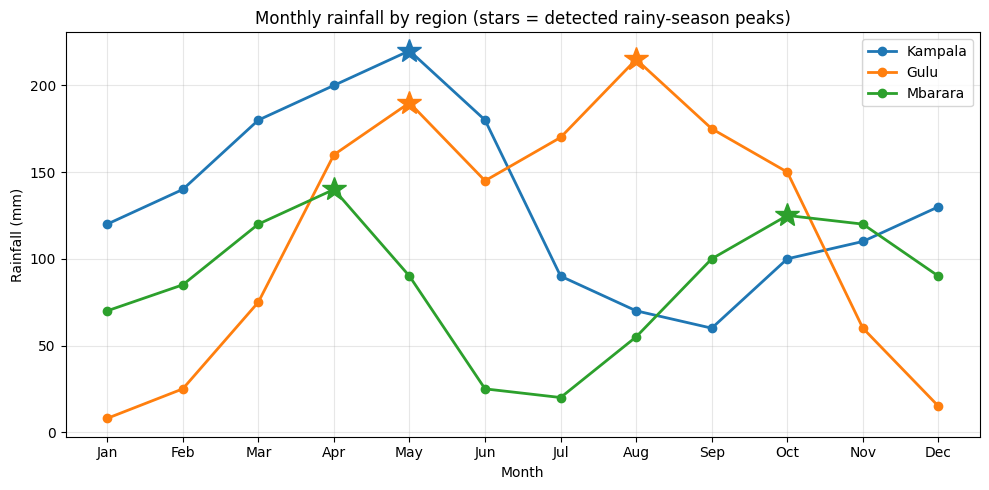

In [16]:
# plot_rainfall_lines comes from src/rainfall/plots.py
plot_rainfall_lines(regions)

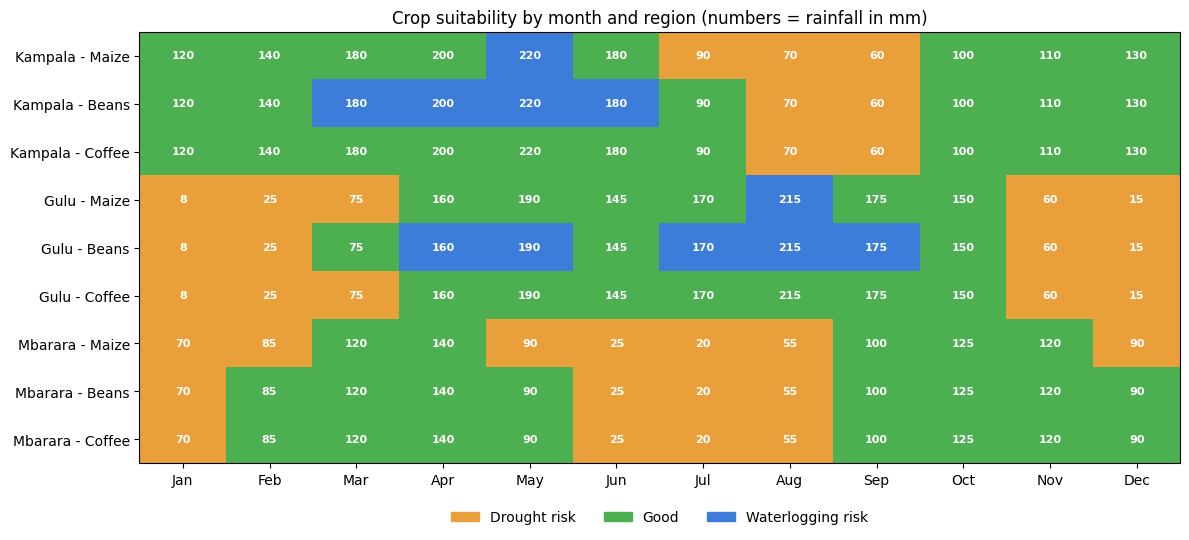

In [17]:
# plot_suitability_heatmap comes from src/rainfall/plots.py
plot_suitability_heatmap(regions, crops)

## 7. Advisory note for farmers (Mbarara)

**Task 7.** A short note (200 words or fewer) saying which crop to grow and when to plant.

First, let the code list the facts the note relies on, so every claim can be checked.

In [18]:
mbarara_rule_rows = []
for crop in crops:
    good = crop.good_months(mbarara)
    mbarara_rule_rows.append({"Crop": crop.crop, "Suitable months": ", ".join(good), "Count": len(good)})

pd.DataFrame(mbarara_rule_rows).set_index("Crop")

,Suitable months,Count
Crop,,
Maize,"Mar, Apr, Sep, Oct, Nov",5
Beans,"Feb, Mar, Apr, May, Sep, Oct, Nov, Dec",8
Coffee,"Feb, Mar, Apr, May, Sep, Oct, Nov, Dec",8


In [19]:
advisory_note = """
ADVICE FOR MBARARA FARMERS

Mbarara has two rainy seasons, so you can plant twice a year.

Season 1 (plant early March): the rains run from March to May, with a dry spell in June to August.
Season 2 (plant early September): the rains run from September to November.

Which crop?
- Beans suit both seasons. They need only about three months, so they finish before the dry months. Plant in March and again in September or October.
- Maize needs about four months and at least 100 mm each month. Plant it right at the start of each season (early March, early September) so the crop uses the best rain.
- Coffee can be planted at the start of either season. In the dry months (June to August, and January) rainfall is below 85 mm, so mulch the trees to keep moisture.

Avoid planting any annual crop in June to August: rainfall drops as low as 20 mm.

Note: this advice uses illustrative rainfall. Please confirm with your local extension officer.
""".strip()

print(advisory_note)

word_count = len(advisory_note.split())
print(f"\nWord count: {word_count}")
assert word_count <= 200, "Note is too long!"

ADVICE FOR MBARARA FARMERS

Mbarara has two rainy seasons, so you can plant twice a year.

Season 1 (plant early March): the rains run from March to May, with a dry spell in June to August.
Season 2 (plant early September): the rains run from September to November.

Which crop?
- Beans suit both seasons. They need only about three months, so they finish before the dry months. Plant in March and again in September or October.
- Maize needs about four months and at least 100 mm each month. Plant it right at the start of each season (early March, early September) so the crop uses the best rain.
- Coffee can be planted at the start of either season. In the dry months (June to August, and January) rainfall is below 85 mm, so mulch the trees to keep moisture.

Avoid planting any annual crop in June to August: rainfall drops as low as 20 mm.

Note: this advice uses illustrative rainfall. Please confirm with your local extension officer.

Word count: 171


## Extension: year-to-year variability with box plots

**Extension.** Replace the illustrative data with at least 10 years of real monthly rainfall (e.g. NASA POWER or UNMA) and show variability as box plots per month.

The function below expects a table with **one row per year** and **one column per month**. I have no internet access to download real data here, so the demo uses **synthetic (made-up) numbers purely to test the function**. When you have your real file, load it with `pd.read_csv(...)`, shape it as described, and call the same function.

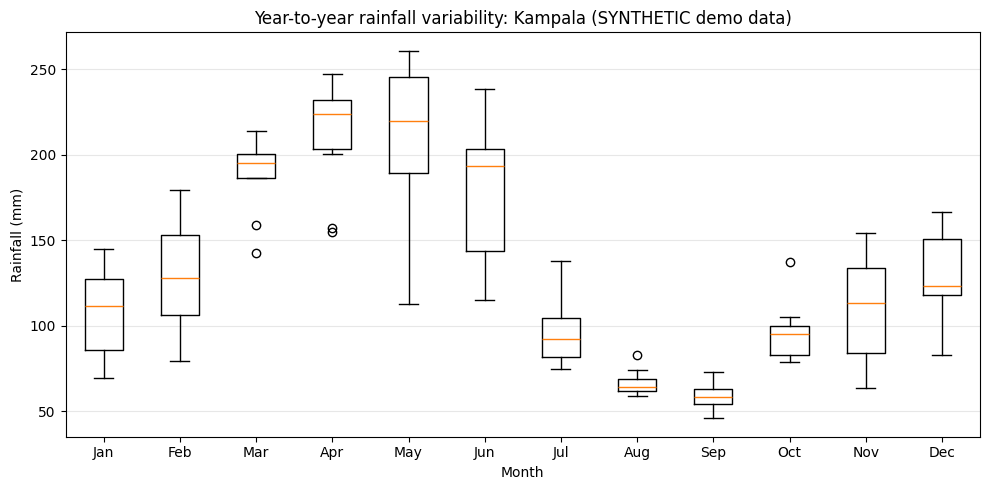

In [20]:
# plot_monthly_boxplots comes from src/rainfall/plots.py
# ---- SYNTHETIC DEMO DATA: replace with real NASA POWER / UNMA data ----
rng = np.random.default_rng(seed=42)              # fixed seed -> same numbers every run
years = range(2014, 2024)                         # 10 years
demo = np.clip(rng.normal(loc=kampala.rainfall, scale=0.25 * kampala.rainfall, size=(10, 12)), 0, None)
demo_df = pd.DataFrame(demo, index=years, columns=MONTHS)

plot_monthly_boxplots(demo_df, "Kampala (SYNTHETIC demo data)")

## Findings & Limitations

**Findings.** Rainfall *amount* and rainfall *pattern* tell different stories. Kampala is the wettest region (1,600 mm a year) and the most evenly spread (CV 37%), while Gulu receives less (1,388 mm) but is the most seasonal (CV 61%): it is almost dry in January yet very wet in August. Mbarara is the driest (1,040 mm), and its rain is concentrated in two seasons (peaks in April and October). For Mbarara, beans and coffee each suit 8 months of the year but maize only 5, so maize is the most rainfall-limited crop and needs the most careful planting date.

The similarity measures disagree on purpose. Cosine similarity rates every pair of regions between 0.75 and 0.89, yet Pearson correlation is near zero (-0.17 to 0.21). Cosine is high mostly because rainfall is never negative, so cosine alone overstates how alike two regions are. A region with exactly double the rain scores a perfect 1 on cosine while Euclidean distance shows a 493 mm gap, so amounts must be compared with distance, not cosine.

**Limitations.** (1) The data is illustrative: one year, no year-to-year variation. (2) Peak detection matched the known zone only for Mbarara; Kampala and Gulu flip between unimodal and bimodal as the prominence setting moves between 10 and 60 mm, so the 40 mm choice is a judgement. (3) Crop thresholds are my monthly conversion of FAO seasonal totals and ignore soil, temperature, crop growth stages and dry spells inside a month. (4) Coefficient of variation is undefined when the mean rainfall is zero. Next step: repeat the analysis with 10+ years of NASA POWER or UNMA data.

## Summary: concepts to be able to explain

| Concept | Where it appeared | One-line explanation |
|---|---|---|
| **Class / object** | `Region`, `CropRule` | A blueprint that bundles data with the functions that use it. |
| **`__init__` validation** | `Region` | Reject bad data the moment the object is created. |
| **Methods vs functions** | `region.annual_total()` vs `pairwise_matrix(...)` | Behaviour of *one* object is a method; work across *many* objects is a function. |
| **Class constants** | `CropRule.GOOD` | Named values instead of unexplained 0/1/2. |
| **Composition** | `CropRule.classify_region(region)` | One class works with another by receiving it as an argument. |
| **Vectorisation** | `rainfall.sum()`, `np.dot` | Do maths on the whole array at once, with no loops. |
| **Functions as arguments** | `pairwise_matrix(regions, measure)` | Write the loop once, swap the measure. |
| **Cosine vs distance** | Sections 3-4 | Cosine = direction (shape), Euclidean = size. |
| **Circular data** | `np.tile` before `find_peaks` | Months wrap around, so Dec sits next to Jan. |

**To reuse this on new data:** add a region to `RAINFALL_DATA`, or a `CropRule` to `crops`, then re-run the notebook.